# 03 - YOLO11s training on PPE-5 (Kaggle)

Executed run: `ppe_yolo11s-2`, 100 epochs on the PPE-5 dataset with 8 classes.
Dataset: `/kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data`.
Saved outputs are preserved from the supplied notebook. Reported metrics use validation; predictions use confidence 0.5.
The logs report 12 skipped training images and 3 skipped validation images with mixed detection/segment labels.
See `reports/yolo11s/README.md` for the recorded results and data-quality notes.


## 1. Cài đặt Ultralytics

In [10]:
import subprocess
import sys
# Giữ PyTorch/CUDA của Kaggle; ghi lại version thực tế trong báo cáo cuối.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.3.0,<9'])


0

## 2. Import thư viện và kiểm tra GPU

In [11]:
import os
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone
import yaml
import torch
import ultralytics
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops, get_num_params
from IPython.display import display, FileLink, Image

WORK_DIR = Path('/kaggle/working')
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
print('Ultralytics:', ultralytics.__version__)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
ALLOW_CPU = False  # Chỉ bật khi chủ động chấp nhận train chậm trên CPU.
if not torch.cuda.is_available() and not ALLOW_CPU:
    raise RuntimeError('Bật Accelerator GPU trong Kaggle Settings, restart session rồi Run All.')
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Ultralytics: 8.4.215
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 3. Dataset path

In [12]:
# Use exactly the dataset requested for this run.
data_path = '/kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data'
data_root = Path(data_path).resolve()
yaml_path = str(data_root / 'data.yaml')
if not Path(yaml_path).is_file():
    raise FileNotFoundError(
        f'Missing {yaml_path}. Attach ppe5-data in Kaggle Input and check the ppe-5/data folder.'
    )
print('Dataset:', data_root)


Dataset: /kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data


## 4. Kiểm tra cấu trúc dataset

In [13]:
# Check the selected dataset before reading its split configuration.
assert data_root.is_dir(), f'Dataset directory does not exist: {data_root}'
print('Available split directories:', sorted(p.name for p in data_root.iterdir() if p.is_dir()))


Available split directories: ['test', 'train', 'valid']


## 5. Đọc data.yaml và sửa path cho phiên Kaggle hiện tại

Cell này giữ nguyên class mapping, chỉ tạo file YAML tạm trỏ tới đúng dataset. `train` và `val` có thể là đường dẫn tương đối hoặc tuyệt đối.

In [14]:
with open(yaml_path, encoding='utf-8') as f:
    data_config = yaml.safe_load(f)
assert isinstance(data_config, dict) and all(k in data_config for k in ('train', 'val', 'names'))
print(yaml.safe_dump(data_config, allow_unicode=True, sort_keys=False))
raw_names = data_config['names']
class_names = ({int(k): str(v) for k, v in raw_names.items()}
               if isinstance(raw_names, dict) else dict(enumerate(raw_names)))
assert sorted(class_names) == list(range(len(class_names))) and class_names, 'Class IDs phải liên tục từ 0.'
if 'nc' in data_config:
    assert int(data_config['nc']) == len(class_names), 'nc không khớp names.'

def resolve_split(value, split):
    if not isinstance(value, str):
        raise ValueError(f'{split}: expected an image directory path.')
    root = Path(data_path).resolve()
    normalized = value.replace('\\', '/')
    declared = Path(normalized)
    candidates = []
    if not declared.is_absolute():
        candidates.append(root / declared)
    # Relocate stale Kaggle/Roboflow paths into the NEW selected dataset first.
    parts = normalized.split('/')
    for marker in ('train', 'valid', 'val', 'test'):
        if marker in parts:
            candidates.append(root.joinpath(*parts[parts.index(marker):]))
    candidates.append(declared if declared.is_absolute() else root / declared)
    for candidate in candidates:
        resolved = candidate.resolve()
        # Never accept a split from another mounted dataset, even if it exists.
        if resolved.is_relative_to(root) and resolved.is_dir():
            return str(resolved)
    raise FileNotFoundError(f'{split}: cannot resolve {value!r} inside {root}. Tried: {candidates}')

train_images_path = resolve_split(data_config['train'], 'train')
val_images_path = resolve_split(data_config['val'], 'val')
train_config = dict(data_config)
train_config.update(path=data_path, train=train_images_path, val=val_images_path)
# Không cho YAML tự tải/chạy bước download ngoài workflow dataset đã attach.
train_config.pop('download', None)
if train_config.get('test'):
    train_config['test'] = resolve_split(train_config['test'], 'test')
else:
    train_config.pop('test', None)
# Validate annotation directories for the splits declared by this dataset.
for split in ('train', 'val', 'test'):
    if split in train_config:
        labels_dir = Path(train_config[split]).parent / 'labels'
        if not labels_dir.is_dir():
            raise FileNotFoundError(f'{split}: missing label directory {labels_dir}')
if Path(train_images_path) == Path(val_images_path):
    raise ValueError('Train and validation must use different directories.')

train_config_path = str(WORK_DIR / 'ppe_train.yaml')
with open(train_config_path, 'w', encoding='utf-8') as f:
    yaml.safe_dump(train_config, f, allow_unicode=True, sort_keys=False)
print('Training YAML:', train_config_path)
print('Classes:', class_names)


names:
- boots
- helmet
- helmet on
- no boots
- no helmet
- no vest
- person
- vest
nc: 8
roboflow:
  license: MIT
  project: ppe-fruwx
  url: https://universe.roboflow.com/constructionsite/ppe-fruwx/dataset/5
  version: 5
  workspace: constructionsite
test: ./test/images
train: ./train/images
val: ./valid/images

Training YAML: /kaggle/working/ppe_train.yaml
Classes: {0: 'boots', 1: 'helmet', 2: 'helmet on', 3: 'no boots', 4: 'no helmet', 5: 'no vest', 6: 'person', 7: 'vest'}


## 6. Đếm ảnh train và validation

In [15]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
def image_files(folder):
    return sorted(p for p in Path(folder).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
train_files = image_files(train_images_path)
val_files = image_files(val_images_path)
train_count, val_count = len(train_files), len(val_files)
print('Train images:', train_count)
print('Validation images:', val_count)
assert train_count > 0 and val_count > 0


Train images: 3537
Validation images: 555


## 7. Load pretrained YOLO11s

In [16]:
model = YOLO('yolo11s.pt')
print('YOLO11s loaded successfully.')

YOLO11s loaded successfully.


## 8. Train YOLO11

Baseline: 100 epochs, image size 640, batch 16. Nếu GPU hết bộ nhớ, giảm batch xuống 8 hoặc 4.

In [17]:
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

results = model.train(
    data=train_config_path,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    project='/kaggle/working/runs',
    name='ppe_yolo11s',
    pretrained=True,
    patience=20,
    save=True,
    plots=True,
    seed=42
)

Ultralytics 8.4.215 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ppe_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_yolo11s-2, nbs=64, nms=None, opset=None, optimize=Fa

## 9. Kiểm tra model đã lưu

In [18]:
# Lấy thư mục thực tế: Ultralytics tự tăng hậu tố khi chạy lại.
run_dir = Path(model.trainer.save_dir)
best_model_path = run_dir / 'weights' / 'best.pt'
last_model_path = run_dir / 'weights' / 'last.pt'
print('Best model:', best_model_path, best_model_path.is_file())
print('Last model:', last_model_path, last_model_path.is_file())
assert best_model_path.is_file(), 'Không tìm thấy best.pt. Kiểm tra log train.'


Best model: /kaggle/working/runs/ppe_yolo11s-2/weights/best.pt True
Last model: /kaggle/working/runs/ppe_yolo11s-2/weights/last.pt True


## 10. Đánh giá best model trên validation

In [19]:
def collect_detection_metrics(metrics, network, image_size):
    # get_flops returns GFLOPs directly; zero signals missing THOP or a profiling failure.
    params = int(get_num_params(network))
    gflops = float(get_flops(network, imgsz=image_size))
    if not gflops > 0:
        raise RuntimeError('Cannot profile GFLOPs. Check ultralytics-thop and rerun this cell.')
    f1_values = metrics.box.f1
    speed = {stage: float(metrics.speed[stage])
             for stage in ('preprocess', 'inference', 'postprocess')}
    return {
        'params': params,
        'params_millions': params / 1e6,
        'gflops': gflops,
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'f1': float(sum(f1_values) / len(f1_values)) if len(f1_values) else 0.0,
        'mAP50': float(metrics.box.map50),
        'mAP50_95': float(metrics.box.map),
        'latency_inference_ms': speed['inference'],
        'latency_preprocess_ms': speed['preprocess'],
        'latency_postprocess_ms': speed['postprocess'],
        'latency_pipeline_ms': sum(speed.values()),
    }


best_model = YOLO(best_model_path)
best_model.fuse()  # Profile the same fused model that validation uses.
metrics = best_model.val(
    data=train_config_path,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    half=False,
    plots=True,
    project='/kaggle/working/runs',
    name='ppe_yolo11s_validation'
)
evaluation = collect_detection_metrics(metrics, best_model.model, IMAGE_SIZE)
print(f"Params (fused): {evaluation['params']:,} ({evaluation['params_millions']:.3f} M)")
print(f"GFLOPs at imgsz={IMAGE_SIZE}: {evaluation['gflops']:.3f}")
print(f"Precision: {evaluation['precision']:.4f}")
print(f"Recall: {evaluation['recall']:.4f}")
print(f"F1 (macro): {evaluation['f1']:.4f}")
print(f"mAP50: {evaluation['mAP50']:.4f}")
print(f"mAP50-95: {evaluation['mAP50_95']:.4f}")
print(f"Latency inference (validation, batch={BATCH_SIZE}): {evaluation['latency_inference_ms']:.3f} ms/image")
print(f"Preprocess + inference + postprocess: {evaluation['latency_pipeline_ms']:.3f} ms/image")


YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.215 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 161.8±66.9 MB/s, size: 80.7 KB)
val: Scanning /kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data/valid/labels... 555 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 555/555 737.1it/s 0.8s0.1s
val: /kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data/valid/images/00107_jpg.rf.7d37f530070595409bdf8c6424f15748.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data/valid/images/Video4_281_jpg.rf.3991985a7d7f521aa1884130d55ec05e.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/input/datasets/duydq206/ppe5-data/ppe-5/data/valid/images/Video4_78_jpg.rf.2d077e71c47815444c30

## 11. mAP50 theo từng class

,class_id,class_name,mAP50
0,0,boots,0.853505
1,1,helmet,0.910230
2,2,helmet on,0.399158
3,3,no boots,0.265863
4,4,no helmet,0.671948
5,5,no vest,0.688004
6,6,person,0.867583
7,7,vest,0.966078


NaN: class không có AP được đánh giá; không tự gán 0.


,Model,Params (M),GFLOPs,P,R,F1,mAP50,mAP50-95,Latency (ms/img)
0,YOLO11s,9.4159,21.4349,0.6098,0.8041,0.6829,0.7028,0.4426,10.3133


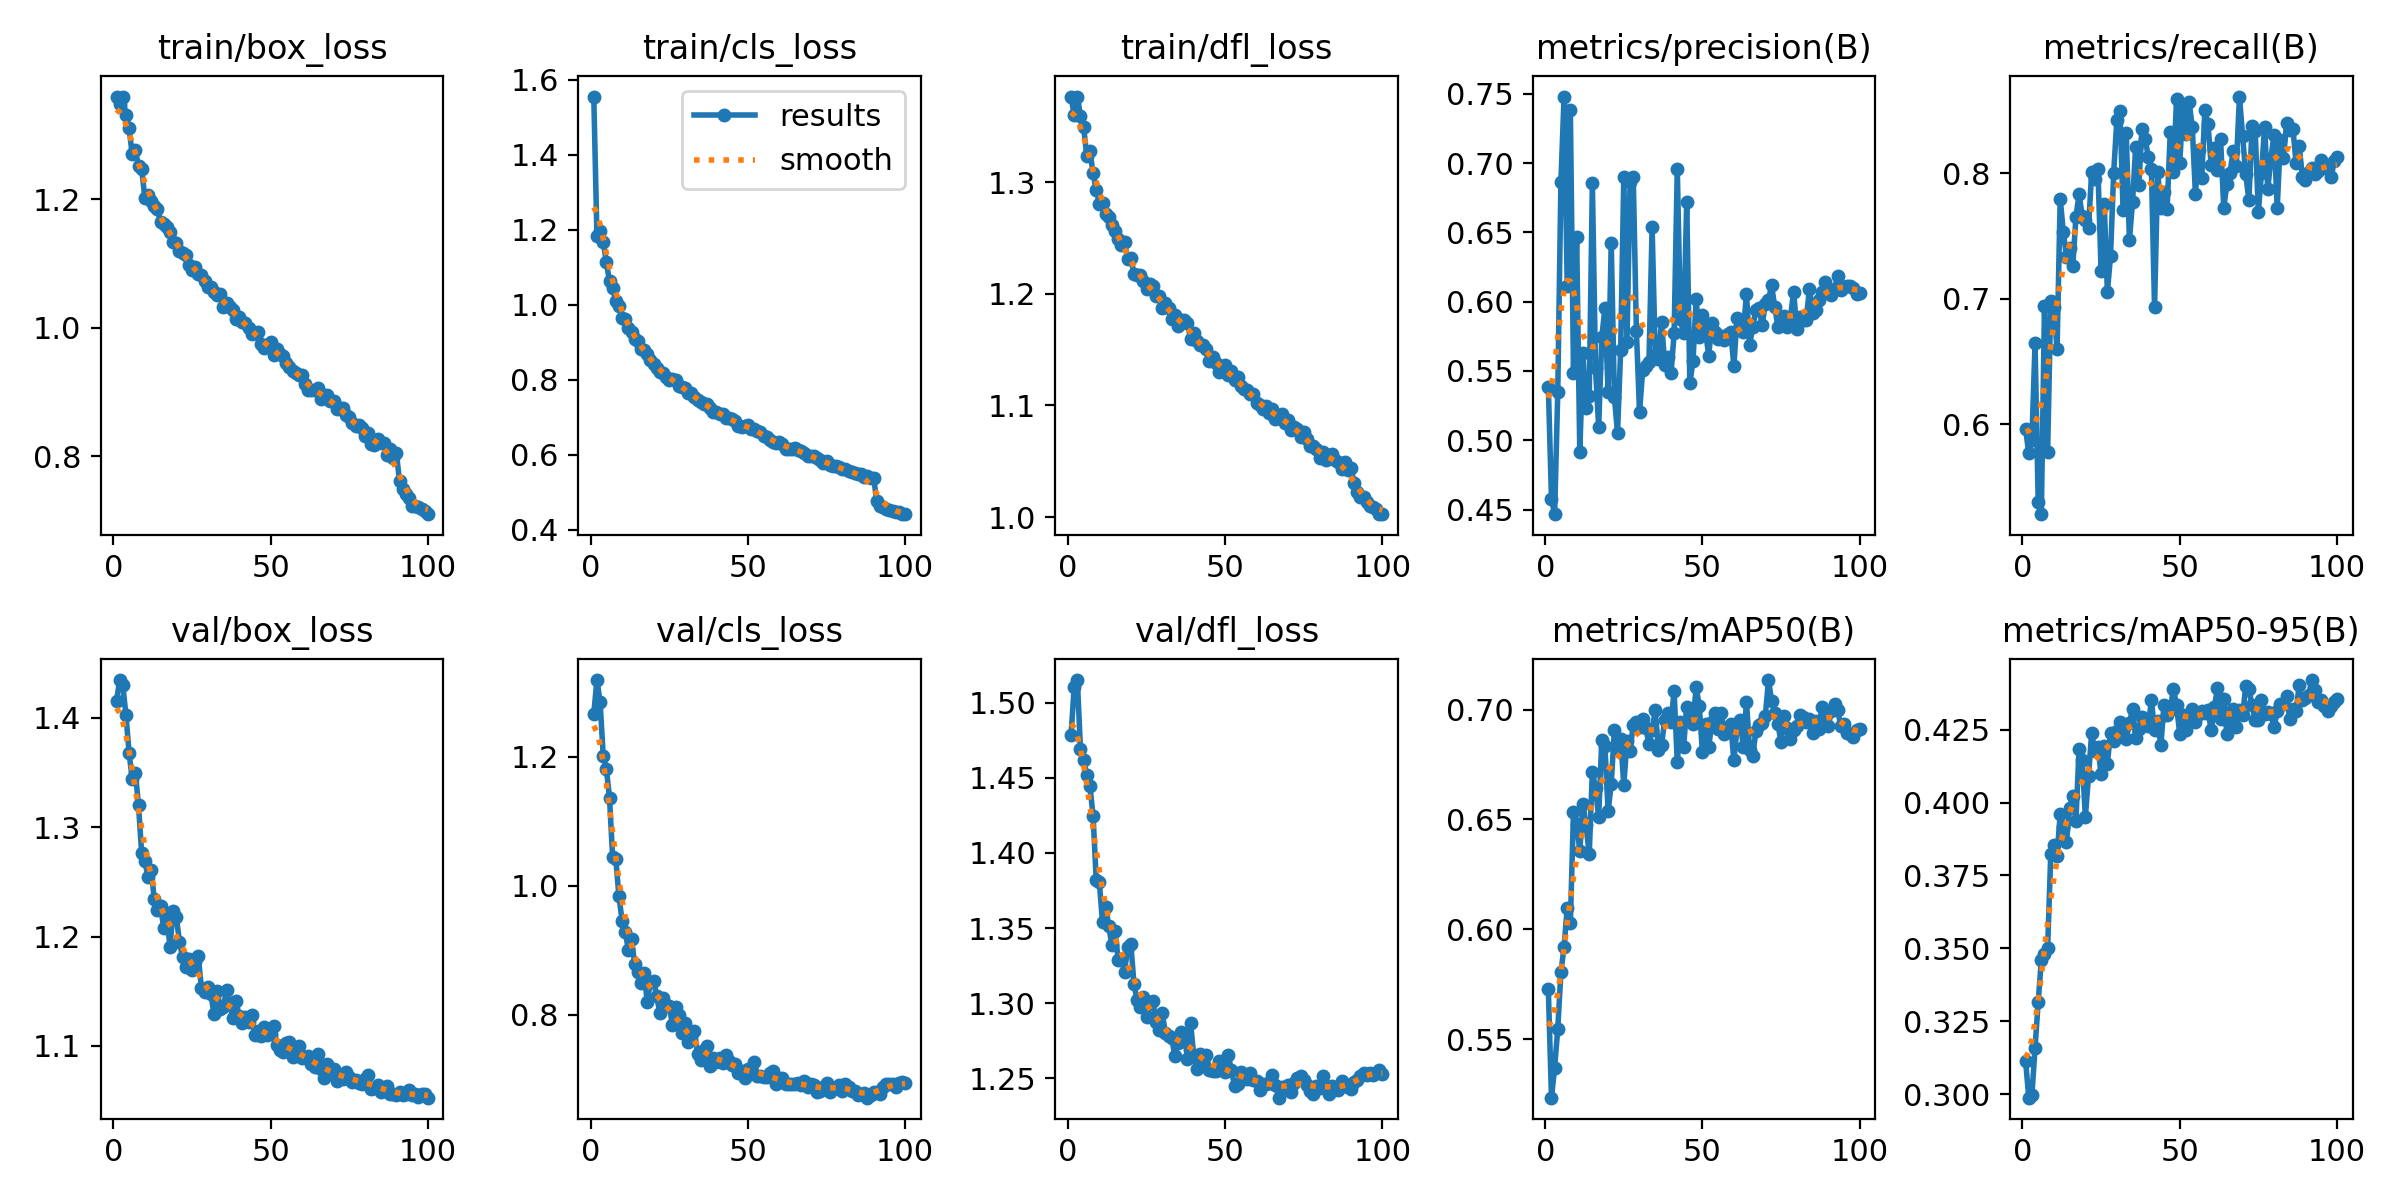

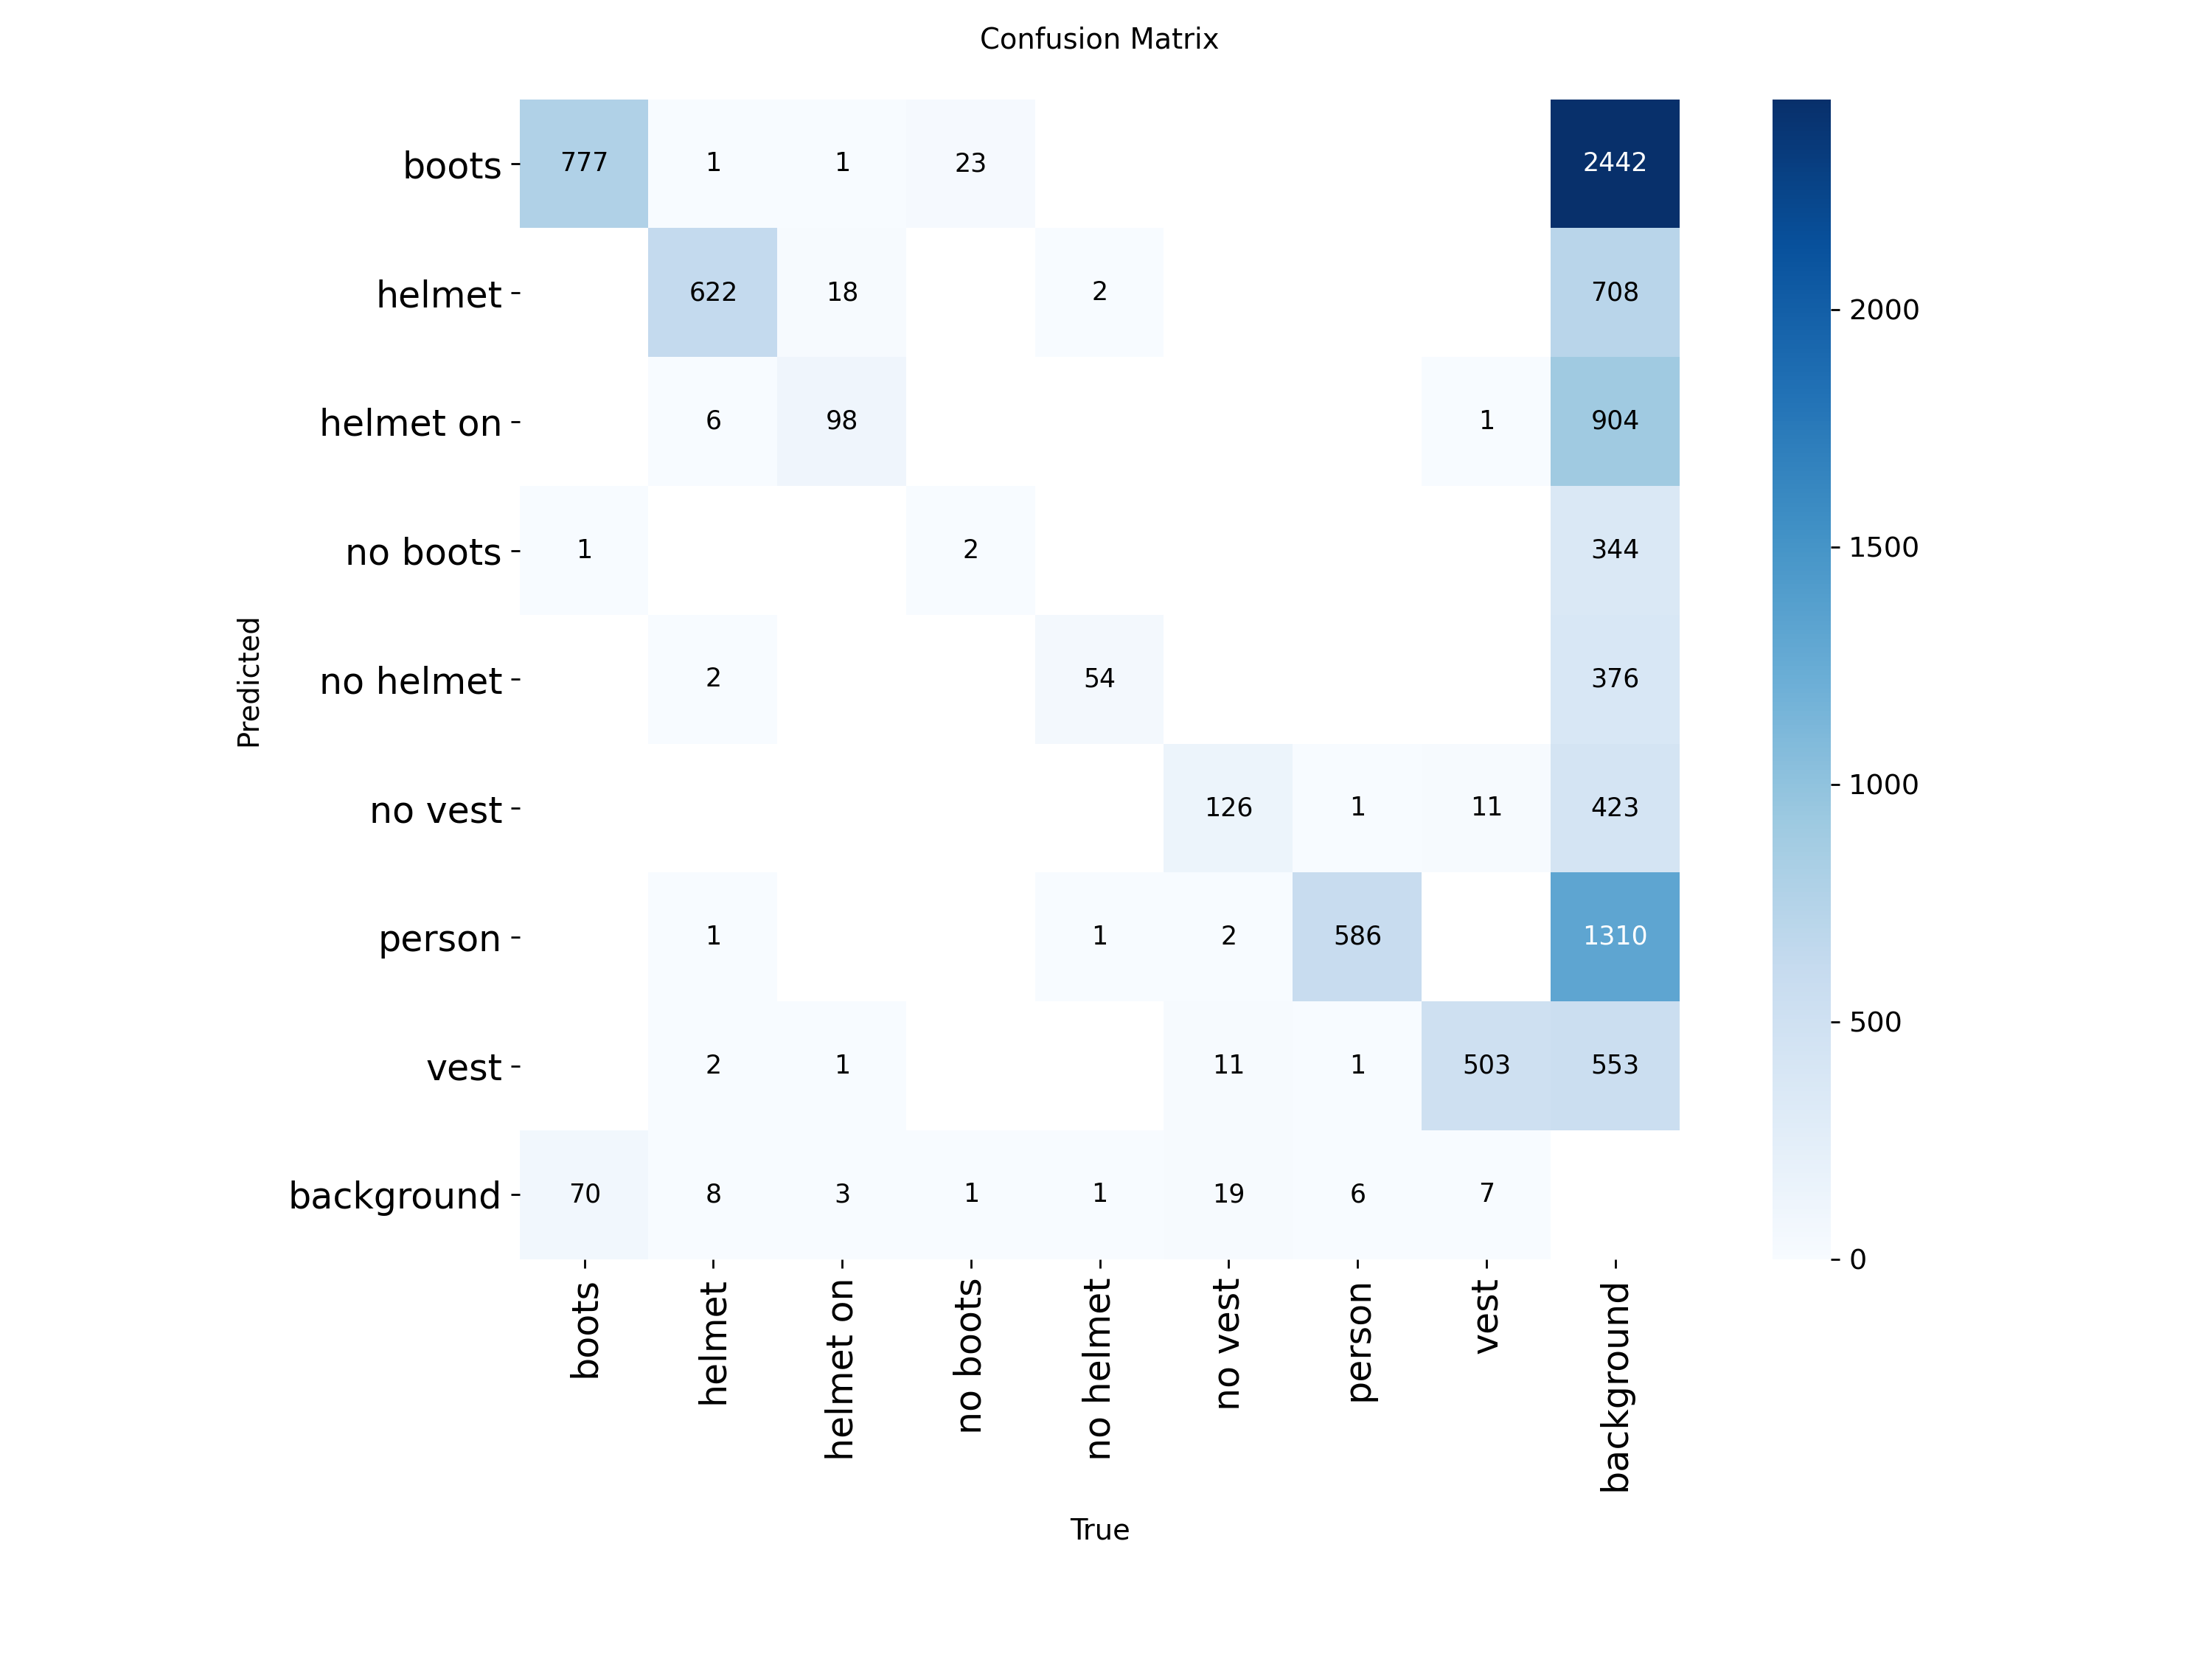

In [20]:
# ap50 chỉ chứa class được đánh giá; ap_class_index ánh xạ về class ID thật.
ap_by_class = {int(cid): float(ap) for cid, ap in zip(metrics.box.ap_class_index, metrics.box.ap50)}
per_class = pd.DataFrame([
    {'class_id': cid, 'class_name': name, 'mAP50': ap_by_class.get(cid, float('nan'))}
    for cid, name in sorted(class_names.items())
])
display(per_class)
print('NaN: class không có AP được đánh giá; không tự gán 0.')
validation_dir = Path(metrics.save_dir)
per_class.to_csv(validation_dir / 'per_class_map50.csv', index=False)
metrics_table = pd.DataFrame([{
    'Model': 'YOLO11s',
    'Params (M)': evaluation['params_millions'],
    'GFLOPs': evaluation['gflops'],
    'P': evaluation['precision'],
    'R': evaluation['recall'],
    'F1': evaluation['f1'],
    'mAP50': evaluation['mAP50'],
    'mAP50-95': evaluation['mAP50_95'],
    'Latency (ms/img)': evaluation['latency_inference_ms'],
}])
display(metrics_table.round(4))
metrics_table.to_csv(validation_dir / 'metrics_summary.csv', index=False)
summary = {
    **evaluation,
    'params_model_state': 'fused',
    'flops_input_shape': [1, 3, IMAGE_SIZE, IMAGE_SIZE],
    'f1_definition': 'Mean per-class F1 at the Ultralytics max-mean-F1 operating point (IoU 0.5)',
    'latency_method': 'Validation average per image; pipeline = preprocess + inference + postprocess; excludes file I/O',
    'latency_batch_size': BATCH_SIZE,
    'latency_precision': 'FP32',
    'device': str(DEVICE),
    'device_name': torch.cuda.get_device_name(DEVICE) if DEVICE != 'cpu' else 'CPU',
    'train_images': train_count, 'val_images': val_count,
    'dataset_path': data_path, 'class_names': class_names, 'split': 'val',
    'model': 'yolo11s.pt', 'ultralytics': ultralytics.__version__,
    'torch': torch.__version__, 'epochs_requested': EPOCHS,
    'imgsz': IMAGE_SIZE, 'batch': BATCH_SIZE, 'seed': 42,
    'train_dir': str(run_dir), 'validation_dir': str(validation_dir),
    'created_utc': datetime.now(timezone.utc).isoformat()
}
with open(validation_dir / 'summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
for plot in (run_dir / 'results.png', validation_dir / 'confusion_matrix.png'):
    if plot.is_file():
        display(Image(filename=str(plot), width=900))


## 12. Predict ảnh validation

Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results saved to /kaggle/working/runs/ppe_yolo11s_predictions
Results 

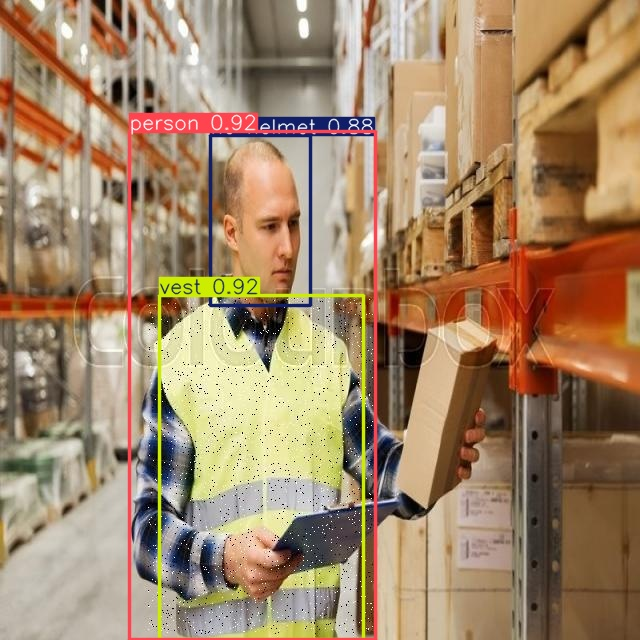

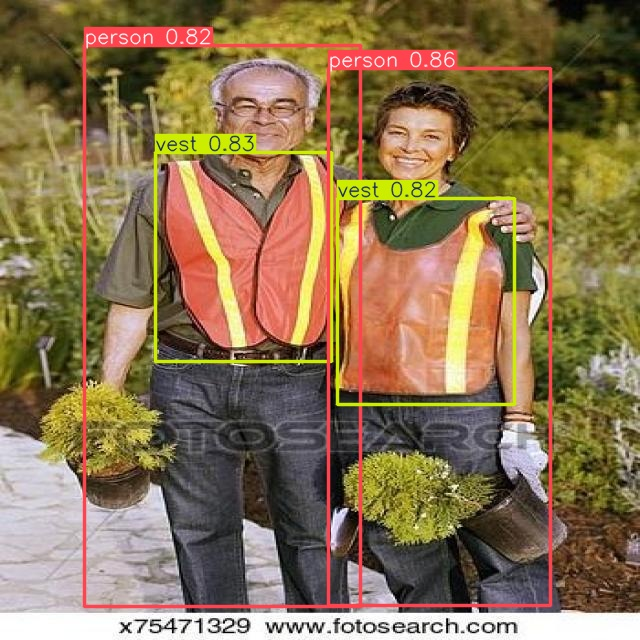

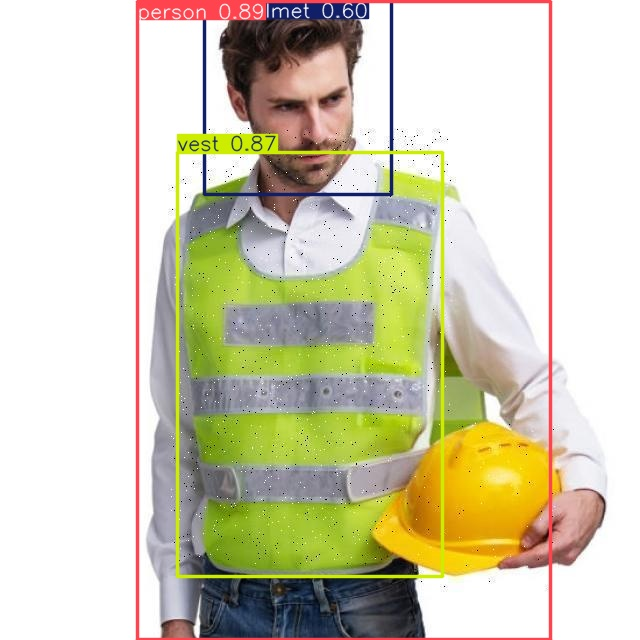

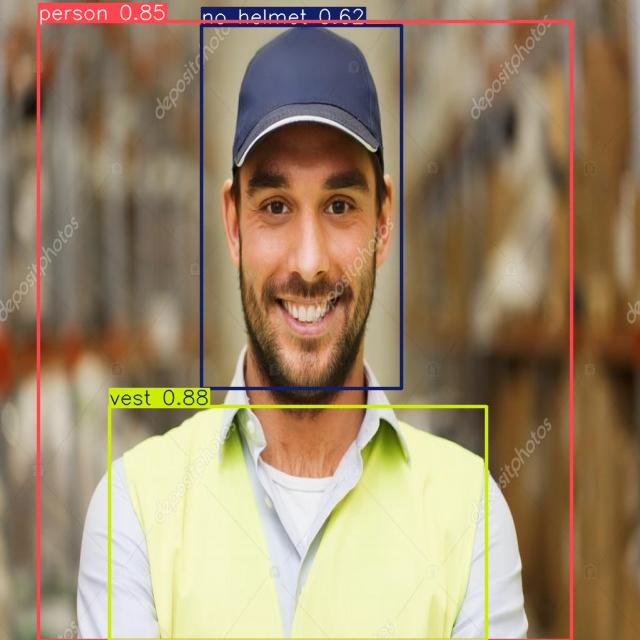

In [26]:

import torch
import gc
from pathlib import Path
from IPython.display import Image, display

gc.collect()
torch.cuda.empty_cache()

prediction_dir = None
prediction_count = 0

for img_path in val_files:
    for prediction in best_model.predict(
        source=str(img_path),  # Chỉ xử lý 1 ảnh mỗi lần
        imgsz=IMAGE_SIZE,
        conf=0.5,
        device=DEVICE,
        save=True,
        stream=True,
        project='/kaggle/working/runs',
        name='ppe_yolo11s_predictions',
        exist_ok=True,
        verbose=False
    ):
        prediction_dir = Path(prediction.save_dir)
        prediction_count += 1

    if prediction_count % 50 == 0:
        print(f"Đã xử lý: {prediction_count}/{len(val_files)}")

print("Predicted images:", prediction_count)
print("Prediction outputs:", prediction_dir)

assert prediction_count == len(val_files)

for preview in image_files(prediction_dir)[:4]:
    display(Image(filename=str(preview), width=700))


## 13. Output cần lưu

ZIP gồm thư mục train thực tế (best.pt, last.pt, results.csv, plots), validation (confusion matrix, summary.json, per_class_map50.csv), prediction và YAML đã chuẩn hóa.
Tên thư mục có thể được Ultralytics thêm hậu tố khi chạy lại; notebook dùng đường dẫn thực tế, không lấy nhầm checkpoint cũ.
Save Version trên Kaggle và giữ output để tải ZIP trong tab Output. FileLink cũng được cung cấp bên dưới.


In [27]:
import zipfile
zip_path = WORK_DIR / f'{run_dir.name}_results.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in (run_dir, validation_dir, prediction_dir):
        for file in sorted(folder.rglob('*')):
            if file.is_file():
                archive.write(file, arcname=str(Path(folder.name) / file.relative_to(folder)))
    archive.write(train_config_path, arcname='ppe_train.yaml')
    archive.writestr('environment.txt', subprocess.check_output(
        [sys.executable, '-m', 'pip', 'freeze'], text=True))
print(f'Đã nén: {zip_path} ({zip_path.stat().st_size / 1024**2:.2f} MB)')
display(FileLink(str(zip_path.relative_to(WORK_DIR))))


Đã nén: /kaggle/working/ppe_yolo11s-2_results.zip (115.48 MB)


/kaggle/working/ppe_yolo11s-2_results.zip